# Peta residual dan enam pilar

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Objek yang sama dengan notebook residual, digambar pada peta.
--> Moran pada rata-rata provinsi, N = 34.
--> Island W = rata-rata pulau.
--> Regresi: `eval2.do`, FGLS grup dan SLX.
--> Gambar: `01 Data/TFP/output/eda/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Patch

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "eda"
EVAL = ROOT / "01 Data" / "TFP" / "output" / "eval"
OUT.mkdir(parents=True, exist_ok=True)

NAVY, CYAN, RED, TEAL, CREAM, PINK, GRAY, KERTAS = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#F2509C", "#797F8C", "#ffffff",
)
PULAU_COLOR = {
    "Sumatera": CREAM, "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PILAR_COLOR = {
    "pendidikan": NAVY, "equity": TEAL, "institusi": "#062E4C",
    "konektivitas": CYAN, "lingkungan": "#30726A", "keamanan": GRAY,
}
MEGA_COLOR = {"primer": GRAY, "sekunder": NAVY, "tersier": CYAN}

rcParams.update({
    "figure.facecolor": KERTAS, "axes.facecolor": KERTAS, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "medium",
})

def save(fig, name):
    p = OUT / name
    fig.savefig(p, dpi=140, bbox_inches="tight", facecolor=KERTAS)
    print("wrote", p.relative_to(ROOT))
    return p

def stars(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

try:
    display
except NameError:
    def display(x):
        print(x)


In [2]:
SECS = list("ABCDEFGHIJKL") + ["MN", "O", "P", "Q", "RSTU"]
PRIMER, SEKUNDER, TERSIER = ["A", "B"], ["C", "D", "E", "F"], ["G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]
EKSTRAKTIF, INDUSTRI, HIJAU_INV = ["A", "B"], ["C", "F"], ["E"]
PADAT_KARYA, PADAT_MODAL = ["A", "C", "F", "G", "I", "P", "Q"], ["B", "D", "H", "J", "K", "L"]
PILAR6 = ["pendidikan", "equity", "institusi", "konektivitas", "lingkungan", "keamanan"]

def _pulau_from_code(c):
    c = int(c)
    if c in (11, 12, 13, 14, 15, 16, 17, 18, 19, 21):
        return "Sumatera"
    if c in (31, 32, 33, 34, 35, 36):
        return "Jawa"
    if c in (51, 52, 53):
        return "Bali-Nusra"
    if c in (61, 62, 63, 64, 65):
        return "Kalimantan"
    if c in (71, 72, 73, 74, 75, 76):
        return "Sulawesi"
    return "Maluku-Papua"

def load_eval_panel():
    for cand in [EVAL / "eval_panel_2017_2025.xlsx", EVAL / "eval_panel.dta", EVAL / "eval_panel.xlsx"]:
        if cand.exists():
            print("load", cand.relative_to(ROOT))
            if cand.suffix == ".dta":
                d = pd.read_stata(cand)
            else:
                d = pd.read_excel(cand, sheet_name="panel")
            d["Pulau"] = d["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})
            return d
    print("eval_panel belum ada — merakit panel deskriptif dari konstruksi + Luaran 2 + Sheet1")
    return build_panel_fallback()

def zscore(s):
    s = pd.to_numeric(s, errors="coerce")
    sd = s.std(ddof=1)
    if sd == 0 or pd.isna(sd):
        return s * np.nan
    return (s - s.mean()) / sd

def build_panel_fallback():
    tfp = pd.read_excel(ROOT / "01 Data" / "TFP" / "output" / "konstruksi" / "TFP Provinsi 2017-2025.xlsx", sheet_name="tfp")
    xlsx = ROOT / "01 Data" / "TFP" / "processed" / "Dataset Agregasi Provinsi Penyetaraan Satuan Miliar Float (keamanan).xlsx"
    if not xlsx.exists():
        xlsx = ROOT / "01 Data" / "TFP" / "AI-Pak_Yudis" / "Dataset Agregasi Provinsi Penyetaraan Satuan Miliar Float (keamanan).xlsx"
    lu = pd.read_excel(xlsx, sheet_name="Analisis Luaran 2")
    s1 = pd.read_excel(xlsx, sheet_name="Sheet1")
    peta = pd.read_csv(ROOT / "01 Data" / "BKPM" / "processed" / "Dataset Provinsi(prov_name).csv")
    peta = peta.dropna(subset=["Code_Prov"]).drop_duplicates("Code_Prov")
    peta["Pulau"] = peta["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})
    lu = lu[(lu.Year >= 2017) & (lu.Year <= 2025)].copy()
    s1 = s1[(s1.Year >= 2017) & (s1.Year <= 2025)].copy()
    keep_s1 = ["Code_Prov", "Year", "Exp_Prov", "Inc_Prov"] + [f"{s}_PMA" for s in SECS] + [f"{s}_PMDN" for s in SECS] + [f"{s}_ADHK" for s in SECS]
    d = tfp.merge(lu.drop(columns=["logtfp_it", "logtfp_it_crs"], errors="ignore"), on=["Code_Prov", "Year"], how="left")
    d = d.merge(s1[keep_s1], on=["Code_Prov", "Year"], how="left")
    d = d.merge(peta[["Code_Prov", "Pulau"]], on="Code_Prov", how="left")
    d["Pulau"] = d["Pulau"].fillna(d["Code_Prov"].map(_pulau_from_code))
    d["lama_sekolah_mean"] = d["Educ_Prov"]
    d["lama_sekolah_harapan"] = d["Heduc_Prov"]
    d["ipm"] = d["IPM_Prov_Nm"]
    d["gini"] = d["Gini_Prov"]
    d["p0"] = d["P0_Prov"]
    d["p1"] = d["Ikk_Prov"]
    d["equality"] = -d["gini"]
    d["upah_rata"] = d["Upah_Agr_Prov"]
    d["rasio_pad"] = d["RasioPAD_Prov"]
    d["apbd_belanja"] = d["Belanja_APBD_Prov"]
    d["apbd_serapan"] = d["Serapan_Prov"]
    d["indeks_demokrasi"] = d["IDI_Prov2"]
    d["indeks_lingkungan"] = d["IKLH_Prov"]
    d["indeks_hijau"] = d["Hijau_Prov"]
    d["indeks_biru"] = d["Biru_Prov"]
    d["pengeluaran_kapita"] = d["Exp_Prov"]
    d["pendapatan_kapita"] = d["Inc_Prov"]
    d["tk_total"] = d[[f"{s}_TenagaKerja" for s in SECS]].sum(axis=1)
    for s in SECS:
        d[f"tk_{s}"] = d[f"{s}_TenagaKerja"]
        d[f"inv_{s}"] = d[f"{s}_PMA"].fillna(0).clip(lower=0) + d[f"{s}_PMDN"].fillna(0).clip(lower=0)
        d[f"share_tk_{s}"] = d[f"tk_{s}"] / d["tk_total"]
        d[f"share_pdrb_{s}"] = d[f"{s}_ADHK"] / d["pdrb_adhk"]
    d["inv_total"] = d[[f"inv_{s}" for s in SECS]].sum(axis=1)
    for s in SECS:
        d[f"share_inv_{s}"] = np.where(d["inv_total"] > 0, d[f"inv_{s}"] / d["inv_total"], 0)
    def bundle(keys, name):
        d[f"share_tk_{name}"] = d[[f"share_tk_{s}" for s in keys]].sum(axis=1)
        d[f"share_inv_{name}"] = d[[f"share_inv_{s}" for s in keys]].sum(axis=1)
        d[f"share_pdrb_{name}"] = d[[f"share_pdrb_{s}" for s in keys]].sum(axis=1)
    bundle(PRIMER, "primer"); bundle(SEKUNDER, "sekunder"); bundle(TERSIER, "tersier")
    bundle(EKSTRAKTIF, "ekstraktif"); bundle(INDUSTRI, "industri"); bundle(HIJAU_INV, "hijau_inv")
    bundle(PADAT_KARYA, "padat_karya"); bundle(PADAT_MODAL, "padat_modal")
    d["inv_sawit"] = d["inv_A"]
    d["share_inv_A"] = d["share_inv_A"]
    d["dominan_tk"] = np.select(
        [d["share_tk_primer"] >= d[["share_tk_sekunder", "share_tk_tersier"]].max(axis=1),
         d["share_tk_sekunder"] >= d[["share_tk_primer", "share_tk_tersier"]].max(axis=1)],
        ["primer", "sekunder"], default="tersier")
    z_educ = zscore(np.log(d["lama_sekolah_mean"] + 1))
    z_heduc = zscore(np.log(d["lama_sekolah_harapan"] + 1))
    z_kampus = zscore(d["APK_Tersier"])
    z_sma = zscore(d["APK_Sekunder2"])
    d["pilar_pendidikan"] = zscore(pd.concat([z_educ, z_heduc, z_sma, z_kampus], axis=1).mean(axis=1))
    d["pilar_equity"] = zscore(pd.concat([
        zscore(np.log(d["ipm"] + 1)), zscore(-np.log(d["p1"] + 1)),
        zscore(d["equality"]), zscore(np.log(d["upah_rata"] + 1)),
        zscore(np.log(d["indeks_demokrasi"] + 1)),
    ], axis=1).mean(axis=1))
    d["pilar_institusi"] = zscore(pd.concat([
        zscore(-np.log(d["PDBDeflator"] + 1)), zscore(np.log(d["rasio_pad"] + 1)),
        zscore(np.log(d["apbd_belanja"] + 1)), zscore(np.log(d["apbd_serapan"] + 1)),
    ], axis=1).mean(axis=1))
    d["pilar_konektivitas"] = zscore(pd.concat([
        zscore(np.log(d["Road_Prov_National"] + 1)), zscore(np.log(d["Cargo_Kapal_Prov"] + 1)),
        zscore(np.log(d["Cargo_KA_Prov"] + 1)), zscore(np.log(d["Airpot_Logis"] + 1)),
    ], axis=1).mean(axis=1))
    d["pilar_lingkungan"] = zscore(pd.concat([
        zscore(np.log(d["indeks_lingkungan"] + 1)), zscore(np.log(d["indeks_hijau"] + 1)),
        zscore(np.log(d["indeks_biru"] + 1)),
    ], axis=1).mean(axis=1))
    d["pilar_keamanan"] = zscore(pd.concat([
        zscore(-np.log(d["CrimeRisk_BPS"] + 1)), zscore(-np.log(d["CR_Prov"] + 1)),
    ], axis=1).mean(axis=1))
    d["idx_solow"] = zscore(d[["pilar_pendidikan", "pilar_equity", "pilar_institusi"]].mean(axis=1))
    d["idx_hard"] = zscore(d[["pilar_konektivitas", "pilar_keamanan"]].mean(axis=1))
    d["idx_fiskal"] = zscore(pd.concat([
        zscore(d["rasio_pad"]), zscore(d["apbd_serapan"]), zscore(np.log(d["apbd_belanja"] + 1)),
    ], axis=1).mean(axis=1))
    d["log_kl"] = d["log_K"] - d["log_L"]
    for col in [f"pilar_{p}" for p in PILAR6] + ["idx_solow", "idx_hard", "idx_fiskal",
                "logtfp_it", "logtfp_it_crs", "indeks_hijau", "ipm", "gini", "p0",
                "share_tk_primer", "share_tk_sekunder", "share_tk_ekstraktif",
                "share_tk_C", "share_inv_A", "share_inv_C", "rasio_pad", "log_kl"]:
        d[f"m_{col}"] = d.groupby("Code_Prov")[col].transform("mean")
    # top5 / bot5 from province means
    pm = d.drop_duplicates("Code_Prov")
    for p in ["pendidikan", "equity", "institusi", "konektivitas", "keamanan"]:
        order = pm.sort_values(f"m_pilar_{p}", ascending=False)["Code_Prov"]
        d[f"top5_{p}"] = d["Code_Prov"].isin(order.head(5)).astype(int)
        d[f"bot5_{p}"] = d["Code_Prov"].isin(order.tail(5)).astype(int)
    med_f = pm["m_idx_fiskal"].median()
    d["d_high_fiskal"] = (d["m_idx_fiskal"] >= med_f).astype(int)
    d["d_sawit"] = (d["m_share_inv_A"] >= pm["m_share_inv_A"].quantile(0.75)).astype(int)
    d["d_ekstraktif"] = (d["m_share_tk_ekstraktif"] >= pm["m_share_tk_ekstraktif"].quantile(0.75)).astype(int)
    d["d_hilir"] = (d["m_share_tk_C"] >= pm["m_share_tk_C"].quantile(0.75)).astype(int)
    d["Pre_Prov"] = d["Pre_Prov"].astype(str).str.strip()
    return d

d = load_eval_panel()
d["Pre_Prov"] = d["Pre_Prov"].astype(str).str.strip()
if "Pulau" not in d.columns:
    d["Pulau"] = d["Code_Prov"].map(_pulau_from_code)
num_cols = d.select_dtypes(include=[np.number]).columns.tolist()
keep_first = [c for c in ["Pre_Prov", "Pulau", "dominan_tk"] if c in d.columns]
agg = {c: "first" for c in keep_first}
for c in num_cols:
    if c in ("Code_Prov", "Year"):
        continue
    agg[c] = "mean"
pm = d.groupby("Code_Prov", as_index=False).agg(agg)
pm["Pulau"] = pm["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})
show_cols = [c for c in ["Code_Prov", "Pre_Prov", "Pulau", "logtfp_it_crs", "idx_solow",
                         "idx_fiskal", "share_tk_primer", "indeks_hijau"] if c in pm.columns]
print(d.shape, "panel", pm.shape, "provinsi", int(d.Year.min()), int(d.Year.max()))
display(pm[show_cols].sort_values("logtfp_it_crs", ascending=False).head(8))


load 01 Data/TFP/output/eval/eval_panel_2017_2025.xlsx
05_eda_spasial.ipynb:2:158: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
(306, 616) panel (34, 614) provinsi 2017 2025


    Code_Prov             Pre_Prov         Pulau  logtfp_it_crs  idx_solow  idx_fiskal  share_tk_primer  indeks_hijau
10         31          DKI Jakarta          Jawa      -0.099577   1.722866    1.351689         0.007974     26.137085
22         64     Kalimantan Timur    Kalimantan      -0.124713   2.170773    0.843234         0.270951     82.277114
32         91          Papua Barat  Maluku-Papua      -0.331663  -0.931945   -0.380982         0.354516    100.000000
23         65     Kalimantan Utara    Kalimantan      -0.414222  -0.165192   -1.168401         0.328861     99.928889
3          14                 Riau      Sumatera      -0.472358   0.183518    0.198788         0.386972     50.612223
9          21             Kep.Riau      Sumatera      -0.548341   0.598088   -0.328549         0.085869     61.236710
4          15                Jambi      Sumatera      -0.691346  -0.173740   -0.416332         0.482009     54.228233
8          19  Kep.Bangka Belitung      Sumatera      -0

In [3]:
import geopandas as gpd

REV = ROOT / "02 Code" / "TFP" / "docs" / "06 Review"
GADM = REV / "assets" / "gadm41_IDN_1.json"
NAME2CODE = {
    "Aceh": 11, "SumateraUtara": 12, "SumateraBarat": 13, "Riau": 14,
    "Jambi": 15, "SumateraSelatan": 16, "Bengkulu": 17, "Lampung": 18,
    "BangkaBelitung": 19, "KepulauanRiau": 21, "JakartaRaya": 31,
    "JawaBarat": 32, "JawaTengah": 33, "Yogyakarta": 34, "JawaTimur": 35,
    "Banten": 36, "Bali": 51, "NusaTenggaraBarat": 52,
    "NusaTenggaraTimur": 53, "KalimantanBarat": 61, "KalimantanTengah": 62,
    "KalimantanSelatan": 63, "KalimantanTimur": 64, "KalimantanUtara": 65,
    "SulawesiUtara": 71, "SulawesiTengah": 72, "SulawesiSelatan": 73,
    "SulawesiTenggara": 74, "Gorontalo": 75, "SulawesiBarat": 76,
    "Maluku": 81, "MalukuUtara": 82, "PapuaBarat": 91, "Papua": 94,
}
RNG = np.random.default_rng(11)

def row_std(W):
    s = W.sum(1, keepdims=True)
    s[s == 0] = 1
    return W / s

def moran(z, W):
    z = np.asarray(z, float)
    z = z - np.nanmean(z)
    den = z @ z
    return float((z @ (W @ z)) / den) if den > 0 else np.nan

def moran_perm(z, W, n=999):
    I0 = moran(z, W)
    hits = 0
    z = np.asarray(z, float)
    for _ in range(n):
        if abs(moran(RNG.permutation(z), W)) >= abs(I0):
            hits += 1
    return I0, (hits + 1) / (n + 1)

def make_W(codes, pulau):
    g = gpd.read_file(GADM)[["NAME_1", "geometry"]]
    g["Code_Prov"] = g.NAME_1.map(NAME2CODE).astype(int)
    g = g.set_index("Code_Prov").loc[list(codes)].to_crs(3857)
    g["geometry"] = g.geometry.simplify(2000, preserve_topology=True)
    n = len(codes)
    xy = np.column_stack([g.centroid.x.values, g.centroid.y.values])
    dist = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(2))
    np.fill_diagonal(dist, np.inf)
    Wq = np.zeros((n, n))
    for i, ci in enumerate(codes):
        gi = g.loc[ci].geometry
        for j in range(i + 1, n):
            if gi.distance(g.loc[codes[j]].geometry) < 1000:
                Wq[i, j] = Wq[j, i] = 1
    for i in range(n):
        if Wq[i].sum() == 0:
            j = int(np.argmin(dist[i]))
            Wq[i, j] = Wq[j, i] = 1
    Wknn = np.zeros((n, n))
    for i in range(n):
        Wknn[i, np.argsort(dist[i])[:4]] = 1
    Wknn = np.maximum(Wknn, Wknn.T)
    Wi = np.zeros((n, n))
    for i, ci in enumerate(codes):
        for j, cj in enumerate(codes):
            if i != j and pulau[ci] == pulau[cj]:
                Wi[i, j] = 1
    Wid = np.zeros((n, n))
    for i in range(n):
        nn = np.argsort(dist[i])[:8]
        Wid[i, nn] = 1.0 / np.maximum(dist[i, nn] / 1000.0, 1.0)
    return {
        "queen": row_std(Wq),
        "knn4": row_std(Wknn),
        "invdist8": row_std(Wid),
        "island": row_std(Wi),
    }, g.reset_index()

def choropleth(g, col, title, fname, cmap="PuBu"):
    fig, ax = plt.subplots(figsize=(8.4, 7.2))
    g.plot(column=col, cmap=cmap, linewidth=0.3, edgecolor="white", ax=ax, legend=True,
           legend_kwds={"shrink": 0.55, "label": col})
    ax.set_axis_off()
    ax.set_title(title)
    fig.tight_layout()
    save(fig, fname)
    plt.show()


In [4]:
codes = pm.Code_Prov.astype(int).tolist()
pulau = dict(zip(pm.Code_Prov.astype(int), pm.Pulau))
Ws, g = make_W(codes, pulau)
g = g.merge(pm, on="Code_Prov", how="left")
print("W queen links", int((Ws["queen"] > 0).sum()), "island links", int((Ws["island"] > 0).sum()))

rows = []
for wname, W in Ws.items():
    for col in ["logtfp_it_crs", "logtfp_it", "idx_solow", "idx_hard", "idx_fiskal",
                "pilar_pendidikan", "pilar_equity", "pilar_institusi", "pilar_konektivitas",
                "pilar_lingkungan", "pilar_keamanan", "indeks_hijau", "rasio_pad",
                "share_tk_primer", "share_inv_padat_karya"]:
        if col not in pm.columns:
            continue
        z = pm.set_index("Code_Prov").loc[codes, col].to_numpy(float)
        I, p = moran_perm(z, W, n=999)
        rows.append({"W": wname, "var": col, "I": I, "p": p})
mor = pd.DataFrame(rows)
mor.to_csv(OUT / "eda2_moran_pilar.csv", index=False)
display(mor.pivot(index="var", columns="W", values="I").round(3))
display(mor.pivot(index="var", columns="W", values="p").round(3))


W queen links 74 island links 188


W                      invdist8  island   knn4  queen
var                                                  
idx_fiskal                0.352   0.492  0.392  0.567
idx_hard                  0.298   0.437  0.332  0.547
idx_solow                 0.178   0.243  0.205  0.333
indeks_hijau              0.599   0.618  0.608  0.690
logtfp_it                 0.233   0.377  0.239  0.479
logtfp_it_crs             0.035   0.077  0.057  0.384
pilar_equity              0.275   0.370  0.320  0.586
pilar_institusi           0.308   0.433  0.344  0.517
pilar_keamanan           -0.005   0.138  0.030  0.202
pilar_konektivitas        0.280   0.409  0.342  0.409
pilar_lingkungan          0.601   0.655  0.591  0.719
pilar_pendidikan         -0.085  -0.225 -0.087  0.062
rasio_pad                 0.444   0.487  0.454  0.583
share_inv_padat_karya    -0.111  -0.157 -0.162 -0.025
share_tk_primer           0.221   0.272  0.209  0.406


W                      invdist8  island   knn4  queen
var                                                  
idx_fiskal                0.001   0.001  0.001  0.001
idx_hard                  0.001   0.001  0.001  0.001
idx_solow                 0.026   0.019  0.043  0.068
indeks_hijau              0.001   0.001  0.001  0.001
logtfp_it                 0.006   0.002  0.014  0.003
logtfp_it_crs             0.716   0.554  0.622  0.031
pilar_equity              0.002   0.001  0.002  0.002
pilar_institusi           0.003   0.002  0.002  0.002
pilar_keamanan            0.975   0.219  0.785  0.256
pilar_konektivitas        0.001   0.001  0.003  0.021
pilar_lingkungan          0.001   0.001  0.001  0.001
pilar_pendidikan          0.339   0.028  0.435  0.731
rasio_pad                 0.001   0.001  0.001  0.001
share_inv_padat_karya     0.220   0.151  0.141  0.896
share_tk_primer           0.007   0.008  0.035  0.026


## Varians peta dan sisa


In [5]:
y = d.logtfp_it.to_numpy()
btw = d.groupby("Code_Prov")["logtfp_it"].transform("mean").to_numpy()
wth = y - btw
dd_y = (d.logtfp_it
        - d.groupby("Code_Prov")["logtfp_it"].transform("mean")
        - d.groupby("Year")["logtfp_it"].transform("mean")
        + d.logtfp_it.mean())
rows = pd.DataFrame([
    ["var overall logtfp DRS", y.var(ddof=1), 1],
    ["pangsa antarprovinsi", btw.var(ddof=1), btw.var(ddof=1) / y.var(ddof=1)],
    ["within-provinsi", wth.var(ddof=1), wth.var(ddof=1) / y.var(ddof=1)],
    ["two-way demean (prov + tahun)", dd_y.var(ddof=1), dd_y.var(ddof=1) / y.var(ddof=1)],
], columns=["bagian", "varians", "pangsa"])
display(rows.round(5))


                          bagian  varians   pangsa
0         var overall logtfp DRS  0.30100  1.00000
1           pangsa antarprovinsi  0.29553  0.98184
2                within-provinsi  0.00547  0.01816
3  two-way demean (prov + tahun)  0.00161  0.00536


## Peta residual: DRS, CRS, gap skala, kuadran CRS

--> DRS = level. CRS = per pekerja. Gap = z(DRS) − z(CRS). Kuadran = level CRS × tren, poin persentase per tahun.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
wrote 01 Data/TFP/output/eda/eda2_map_drs.png
wrote 01 Data/TFP/output/eda/eda2_map_crs.png
wrote 01 Data/TFP/output/eda/eda2_map_scale_gap.png
wrote 01 Data/TFP/output/eda/eda2_map_quadrant_crs.png


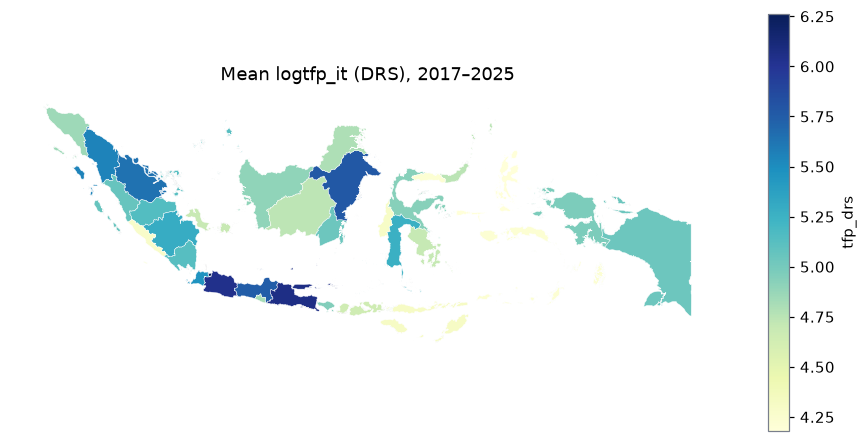

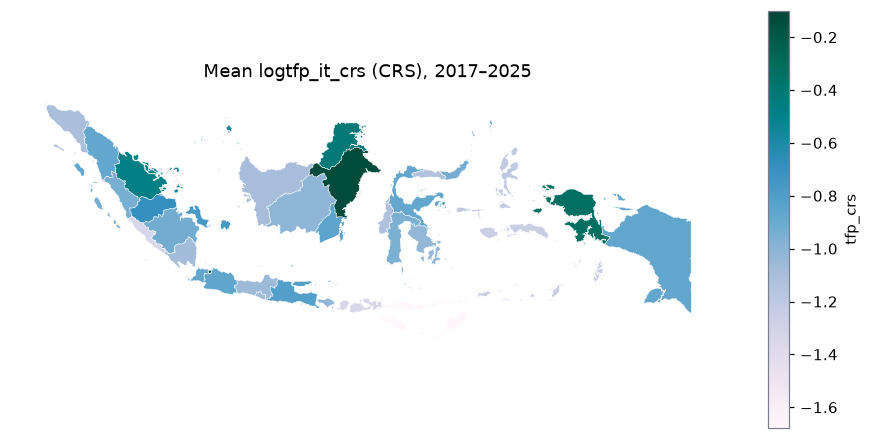

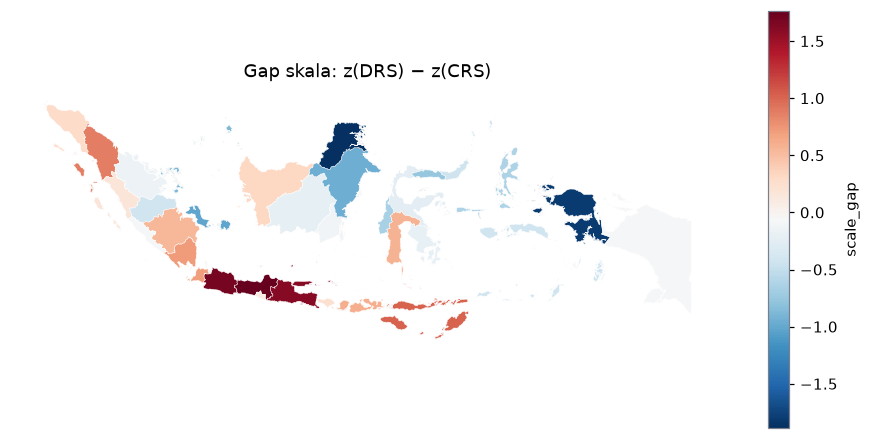

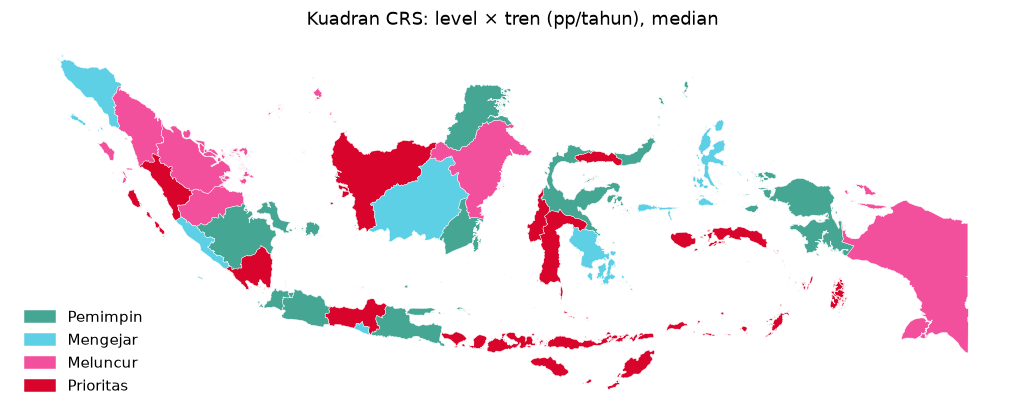

            n
kuadran      
Meluncur    6
Mengejar    6
Pemimpin   11
Prioritas  11


In [6]:
gmap = g.copy()
if "logtfp_it" in gmap.columns:
    gmap["tfp_drs"] = gmap["logtfp_it"]
    gmap["tfp_crs"] = gmap["logtfp_it_crs"]
    z_drs = (gmap.tfp_drs - gmap.tfp_drs.mean()) / gmap.tfp_drs.std(ddof=1)
    z_crs = (gmap.tfp_crs - gmap.tfp_crs.mean()) / gmap.tfp_crs.std(ddof=1)
    gmap["scale_gap"] = z_drs - z_crs

choropleth(gmap, "tfp_drs", "Mean logtfp_it (DRS), 2017–2025", "eda2_map_drs.png", "YlGnBu")
choropleth(gmap, "tfp_crs", "Mean logtfp_it_crs (CRS), 2017–2025", "eda2_map_crs.png", "PuBuGn")
choropleth(gmap, "scale_gap", "Gap skala: z(DRS) − z(CRS)", "eda2_map_scale_gap.png", "RdBu_r")

tr_rows = []
for code, gg in d.sort_values("Year").groupby("Code_Prov"):
    ok = gg.logtfp_it_crs.notna()
    if ok.sum() >= 3:
        sl = np.polyfit(gg.loc[ok, "Year"].astype(float),
                        gg.loc[ok, "logtfp_it_crs"].astype(float), 1)[0]
    else:
        sl = np.nan
    tr_rows.append({"Code_Prov": code, "crs_trend": sl})
gmap = gmap.merge(pd.DataFrame(tr_rows), on="Code_Prov", how="left")
lm, tm = gmap["tfp_crs"].median(), gmap["crs_trend"].median()

def quad(r):
    if r.tfp_crs >= lm and r.crs_trend >= tm:
        return "Pemimpin"
    if r.tfp_crs >= lm:
        return "Meluncur"
    if r.crs_trend >= tm:
        return "Mengejar"
    return "Prioritas"

gmap["kuadran"] = gmap.apply(quad, axis=1)
qcolor = {"Pemimpin": TEAL, "Mengejar": CYAN, "Meluncur": PINK, "Prioritas": RED}
fig, ax = plt.subplots(figsize=(9.2, 5.2), constrained_layout=True)
gmap.plot(color=gmap.kuadran.map(qcolor), linewidth=0.3, edgecolor="white", ax=ax)
ax.set_title("Kuadran CRS: level × tren (pp/tahun), median")
ax.set_axis_off()
handles = [plt.Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in qcolor.items()]
ax.legend(handles=handles, loc="lower left", frameon=False)
save(fig, "eda2_map_quadrant_crs.png")
plt.show()
display(gmap.groupby("kuadran")[["Pre_Prov"]].count().rename(columns={"Pre_Prov": "n"}))


## Moran I (999 permutasi)


In [7]:
from numpy.linalg import lstsq

D = pd.get_dummies(pm["Pulau"], drop_first=True).to_numpy(float)
yb = pm["logtfp_it"].to_numpy(float)
yc = pm["logtfp_it_crs"].to_numpy(float)
Xisl = np.column_stack([np.ones(len(yb)), D])
b_isl, *_ = lstsq(Xisl, yb, rcond=None)
r2_isl = 1 - ((yb - Xisl @ b_isl) ** 2).sum() / ((yb - yb.mean()) ** 2).sum()
y_isl = yb - Xisl @ b_isl
print(f"R² kelompok pulau pada mean DRS = {r2_isl:.3f}")
if "island" in Ws:
    print(f"corr(W_pulau y, fitted pulau) = {np.corrcoef(Ws['island'] @ yb, Xisl @ b_isl)[0,1]:.3f}")
print("(island W tidak memisahkan spillover dari intersep kelompok)")

dd_y = (d.logtfp_it
        - d.groupby("Code_Prov")["logtfp_it"].transform("mean")
        - d.groupby("Year")["logtfp_it"].transform("mean")
        + d.logtfp_it.mean())
e2024 = (d.assign(_dd=dd_y).loc[d.Year == d.Year.max()]
           .sort_values("Code_Prov")["_dd"].to_numpy())

rows = []
series = [("mean DRS", yb), ("mean CRS", yc), ("DRS | island FE", y_isl)]
if len(e2024) == len(yb):
    series.append((f"sisa two-way {int(d.Year.max())}", e2024))
for label, z in series:
    for name, W in Ws.items():
        I, p = moran_perm(z, W)
        rows.append({"seri": label, "W": name, "I": round(I, 3), "p_perm": round(p, 3)})
mor_res = pd.DataFrame(rows)
mor_res.to_csv(OUT / "eda2_moran.csv", index=False)
display(mor_res)


R² kelompok pulau pada mean DRS = 0.485
corr(W_pulau y, fitted pulau) = 0.973
(island W tidak memisahkan spillover dari intersep kelompok)
05_eda_spasial.ipynb:10:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`


                 seri         W      I  p_perm
0            mean DRS     queen  0.479   0.006
1            mean DRS      knn4  0.239   0.015
2            mean DRS  invdist8  0.233   0.008
3            mean DRS    island  0.377   0.004
4            mean CRS     queen  0.384   0.033
5            mean CRS      knn4  0.057   0.600
6            mean CRS  invdist8  0.035   0.698
7            mean CRS    island  0.077   0.538
8     DRS | island FE     queen -0.062   0.729
9     DRS | island FE      knn4 -0.231   0.026
10    DRS | island FE  invdist8 -0.152   0.069
11    DRS | island FE    island -0.211   0.039
12  sisa two-way 2025     queen -0.079   0.520
13  sisa two-way 2025      knn4 -0.007   0.949
14  sisa two-way 2025  invdist8  0.059   0.451
15  sisa two-way 2025    island -0.024   0.826


## SAR between N = 34


In [8]:
from numpy.linalg import slogdet, lstsq
from scipy.optimize import minimize

def sar_nll(rho, y, X, W):
    rho = float(np.asarray(rho).reshape(-1)[0])
    if not (-0.95 < rho < 0.95):
        return 1e12
    n = W.shape[0]
    sign, ld = slogdet(np.eye(n) - rho * W)
    if sign <= 0:
        return 1e12
    Ay = y - rho * (W @ y)
    b, *_ = lstsq(X, Ay, rcond=None)
    e = Ay - X @ b
    sig2 = float(e @ e / n)
    if sig2 <= 1e-12:
        return 1e12
    return 0.5 * n * np.log(2 * np.pi * sig2) - ld + 0.5 * n

def fit_sar(y, X, W):
    X = np.column_stack([np.ones(len(y)), X])
    res = minimize(lambda r: sar_nll(r, y, X, W), [0.2], method="L-BFGS-B", bounds=[(-0.9, 0.9)])
    rho = float(res.x[0])
    Ay = y - rho * (W @ y)
    b, *_ = lstsq(X, Ay, rcond=None)
    f0 = sar_nll(rho, y, X, W)
    eps = 1e-4
    hess = (sar_nll(rho + eps, y, X, W) - 2 * f0 + sar_nll(rho - eps, y, X, W)) / eps ** 2
    se = float(np.sqrt(1 / hess)) if hess > 0 else np.nan
    return rho, se, b, -float(res.fun)

specs = []
x_mentah = [c for c in ["z_ln_ipm", "z_ln_kargo_kapal", "z_ln_crime_risk"] if c in pm.columns]
if len(x_mentah) == 3:
    specs.append(("mentah", x_mentah, ["IPM", "kargo", "keamanan"]))
x_idx = [c for c in ["idx_solow", "idx_hard"] if c in pm.columns]
if len(x_idx) == 2:
    specs.append(("dua rata-rata", x_idx, ["pendidikan-equity-institusi", "konektivitas-keamanan"]))

sar_rows = []
yb = pm["logtfp_it"].to_numpy(float)
for spec, cols, names in specs:
    Xb = pm[cols].to_numpy(float)
    Xols = np.column_stack([np.ones(len(yb)), Xb])
    bols, *_ = lstsq(Xols, yb, rcond=None)
    r2 = 1 - ((yb - Xols @ bols) ** 2).sum() / ((yb - yb.mean()) ** 2).sum()
    print(f"OLS mean, {spec}: R² = {r2:.3f}",
          "  ".join(f"{n}={b:.3f}" for n, b in zip(names, bols[1:])))
    for wname, W in Ws.items():
        rho, se, bhat, ll = fit_sar(yb, Xb, W)
        z = rho / se if se == se and se > 0 else np.nan
        row = {"spec": spec, "W": wname, "rho": round(rho, 3),
               "se": round(se, 3) if se == se else np.nan,
               "z": round(z, 2) if z == z else np.nan, "ll": round(ll, 1),
               "ols_r2": round(r2, 3)}
        for n, b in zip(names, bhat[1:]):
            row[f"b_{n}"] = round(b, 3)
        sar_rows.append(row)
        print(f"  {spec:16s} {wname:10s}  rho={rho:6.3f} (SE {se:.3f})  z={z:5.2f}")
sar = pd.DataFrame(sar_rows)
sar.to_csv(OUT / "eda2_sar_between.csv", index=False)
display(sar)


OLS mean, mentah: R² = 0.716 IPM=0.054  kargo=0.439  keamanan=-0.021
  mentah           queen       rho= 0.161 (SE 0.111)  z= 1.45
  mentah           knn4        rho=-0.059 (SE 0.186)  z=-0.32
  mentah           invdist8    rho=-0.125 (SE 0.210)  z=-0.59
  mentah           island      rho= 0.053 (SE 0.169)  z= 0.31
OLS mean, dua rata-rata: R² = 0.669 pendidikan-equity-institusi=0.244  konektivitas-keamanan=0.386
  dua rata-rata    queen       rho= 0.122 (SE 0.115)  z= 1.06
  dua rata-rata    knn4        rho=-0.226 (SE 0.179)  z=-1.26
  dua rata-rata    invdist8    rho=-0.129 (SE 0.196)  z=-0.66
  dua rata-rata    island      rho=-0.067 (SE 0.169)  z=-0.40


            spec         W    rho     se     z   ll  ols_r2  b_IPM  b_kargo  b_keamanan  b_pendidikan-equity-institusi  b_konektivitas-keamanan
0         mentah     queen  0.161  0.111  1.45 -5.1   0.716  0.036    0.418      -0.054                            NaN                      NaN
1         mentah      knn4 -0.059  0.186 -0.32 -6.0   0.716  0.065    0.440      -0.009                            NaN                      NaN
2         mentah  invdist8 -0.125  0.210 -0.59 -5.9   0.716  0.073    0.444       0.001                            NaN                      NaN
3         mentah    island  0.053  0.169  0.31 -6.0   0.716  0.045    0.435      -0.032                            NaN                      NaN
4  dua rata-rata     queen  0.122  0.115  1.06 -8.1   0.669    NaN      NaN         NaN                          0.226                    0.358
5  dua rata-rata      knn4 -0.226  0.179 -1.26 -7.9   0.669    NaN      NaN         NaN                          0.278                  

## Peta 6 pilar, TFP CRS, kapasitas fiskal

--> Fiskal = PAD, serapan, dan log belanja.


wrote 01 Data/TFP/output/eda/eda2_map_tfp_crs.png
wrote 01 Data/TFP/output/eda/eda2_map_idx_solow.png
wrote 01 Data/TFP/output/eda/eda2_map_idx_hard.png
wrote 01 Data/TFP/output/eda/eda2_map_fiskal.png
wrote 01 Data/TFP/output/eda/eda2_map_hijau.png


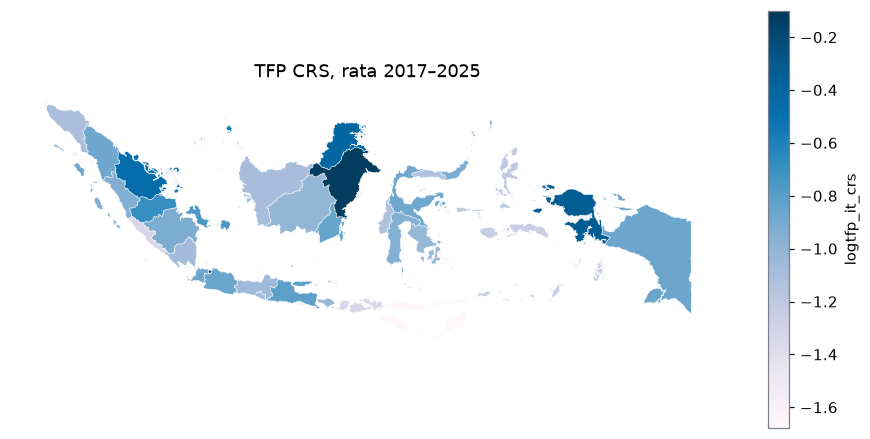

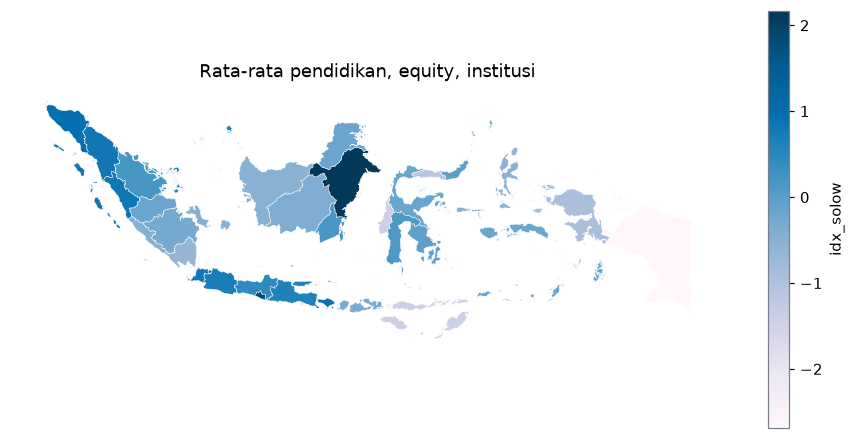

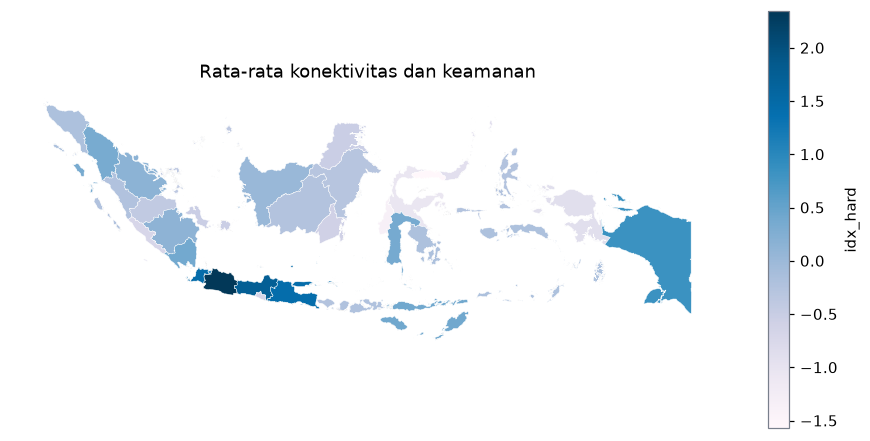

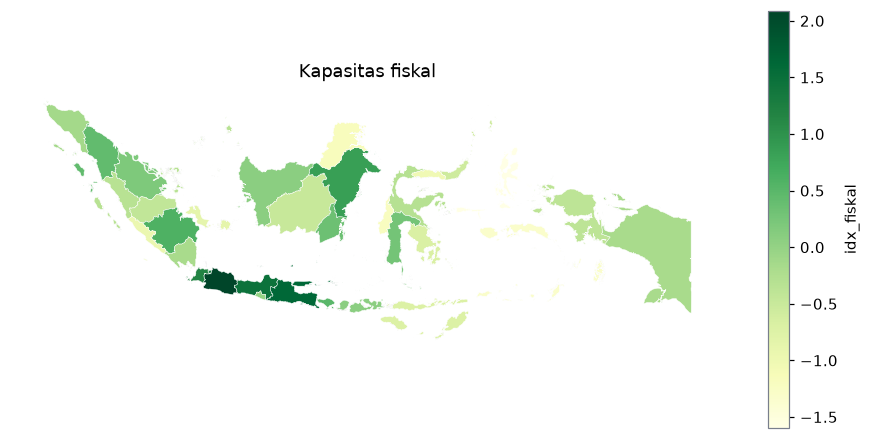

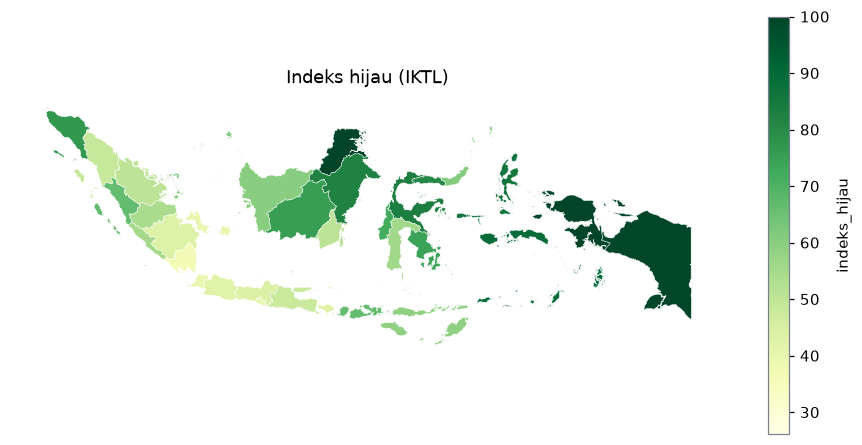

In [9]:
choropleth(g, "logtfp_it_crs", "TFP CRS, rata 2017–2025", "eda2_map_tfp_crs.png", "PuBu")
choropleth(g, "idx_solow", "Rata-rata pendidikan, equity, institusi", "eda2_map_idx_solow.png", "PuBu")
choropleth(g, "idx_hard", "Rata-rata konektivitas dan keamanan", "eda2_map_idx_hard.png", "PuBu")
choropleth(g, "idx_fiskal", "Kapasitas fiskal", "eda2_map_fiskal.png", "YlGn")
choropleth(g, "indeks_hijau", "Indeks hijau (IKTL)", "eda2_map_hijau.png", "YlGn")


wrote 01 Data/TFP/output/eda/eda2_map_6pilar.png


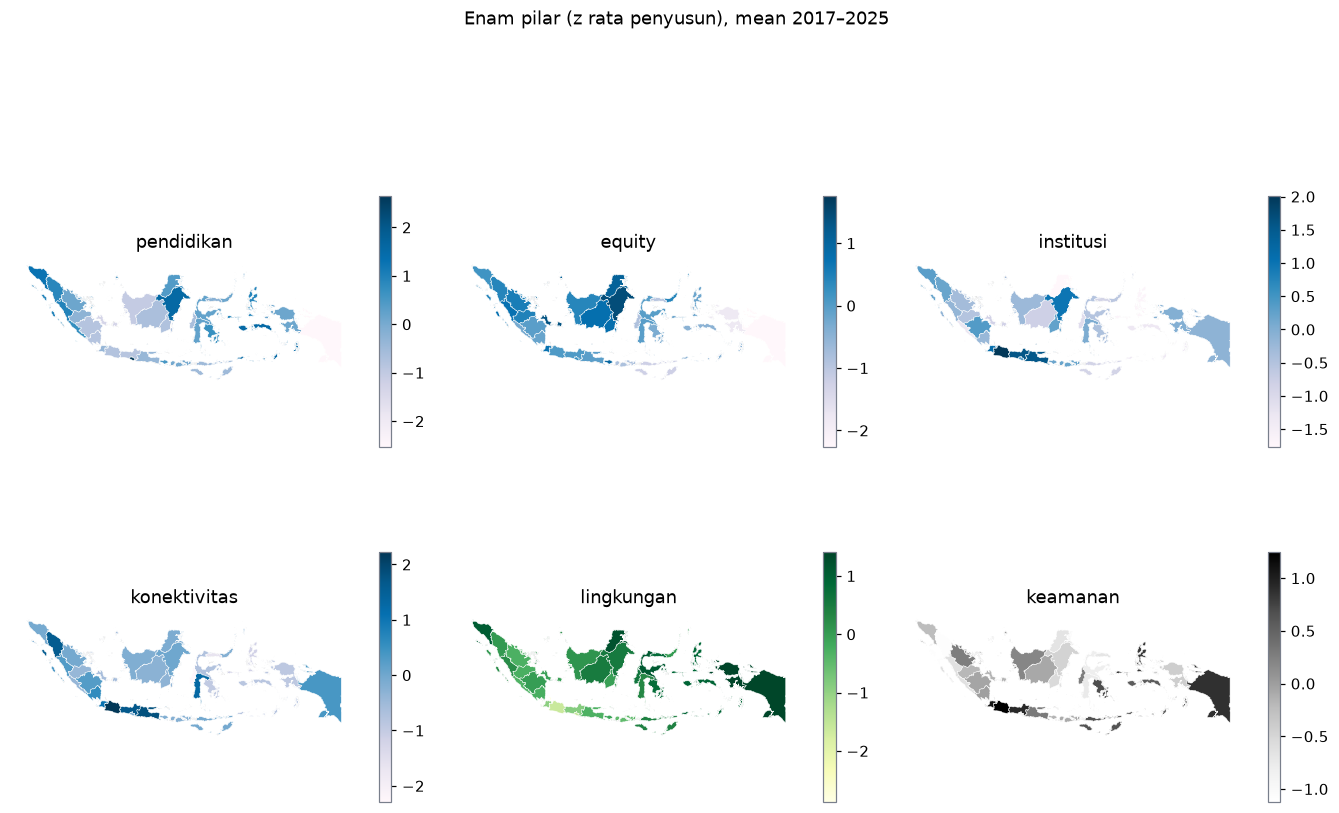

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12.4, 8.4))
cmaps = ["PuBu", "PuBu", "PuBu", "PuBu", "YlGn", "Greys"]
for ax, p, cm in zip(axes.ravel(), PILAR6, cmaps):
    g.plot(column=f"pilar_{p}", cmap=cm, linewidth=0.3, edgecolor="white", ax=ax, legend=True,
           legend_kwds={"shrink": 0.5})
    ax.set_axis_off()
    ax.set_title(p)
fig.suptitle("Enam pilar (z rata penyusun), mean 2017–2025", y=1.01)
fig.tight_layout()
save(fig, "eda2_map_6pilar.png")
plt.show()


## Dominasi sektoral, sawit, kantong lemah


/Users/athamawardi/miniconda3/envs/playgroundenv/lib/python3.14/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/Users/athamawardi/miniconda3/envs/playgroundenv/lib/python3.14/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
/Users/athamawardi/miniconda3/envs/playgroundenv/lib/python3.14/site-packages/geopandas/geodataframe.py:1969: PerformanceWarning: DataFrame is highly fragment

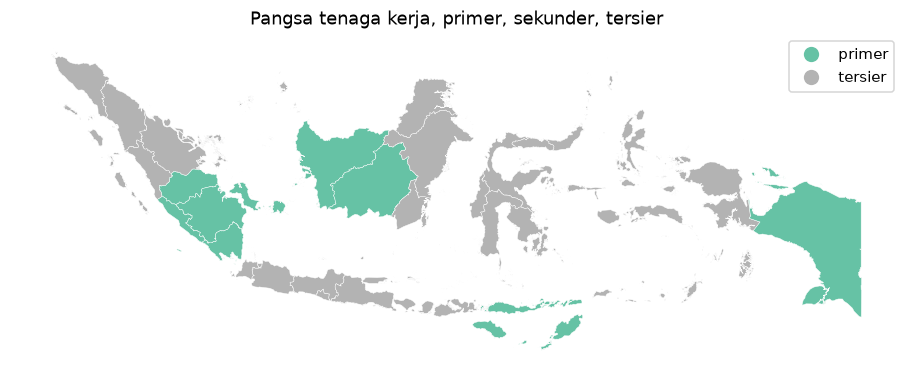

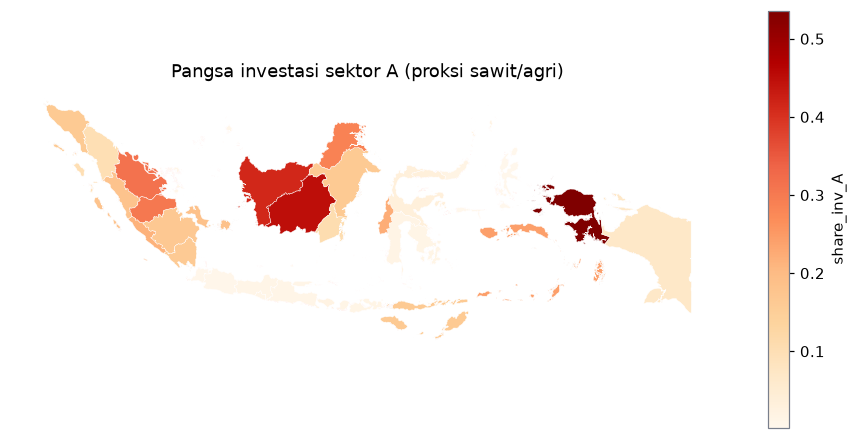

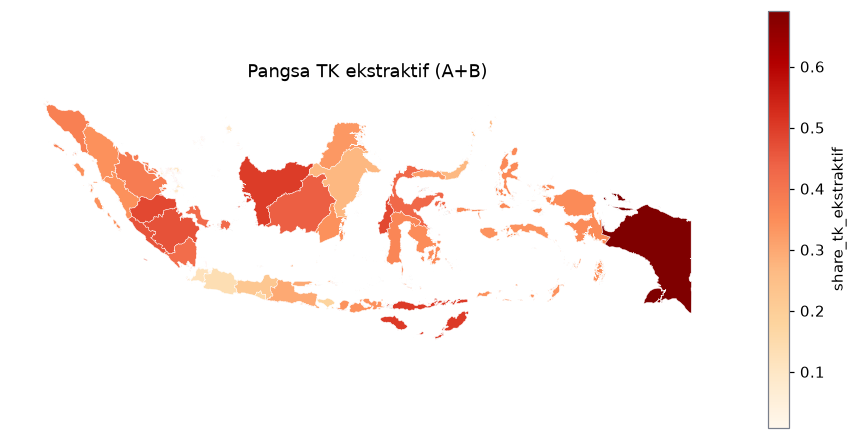

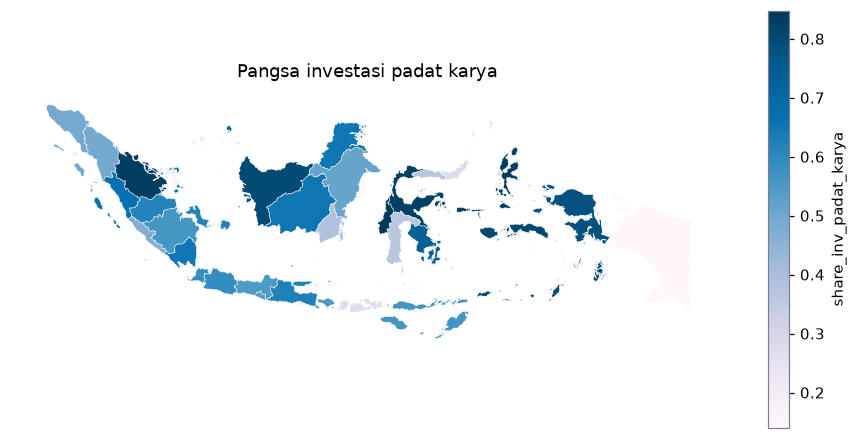

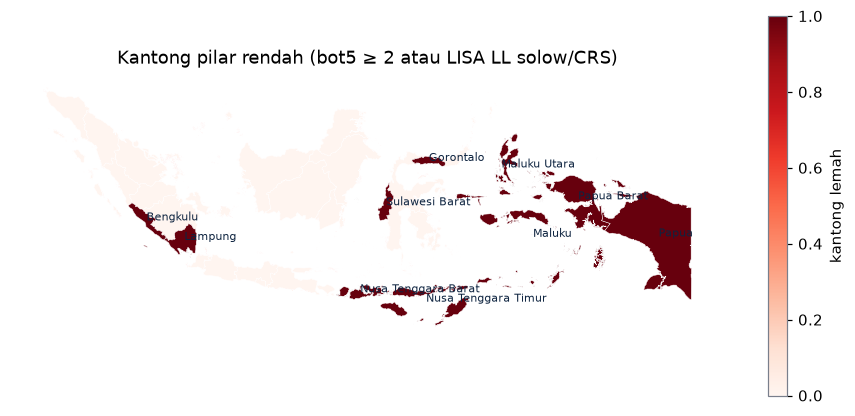

               Pre_Prov         Pulau  n_bot5 lisa_idx_solow lisa_idx_fiskal lisa_logtfp_it_crs  logtfp_it_crs  idx_solow  idx_fiskal  share_tk_primer  indeks_hijau
33                Papua  Maluku-Papua     2.0             LL              LL                 HH      -0.869779  -2.687316   -0.184167         0.691826     99.183807
18  Nusa Tenggara Timur    Bali-Nusra     1.0             LL              LH                 LL      -1.678369  -1.419695   -0.709173         0.504704     58.906847
29       Sulawesi Barat      Sulawesi     2.0             LH              LH                 LL      -1.128206  -1.419443   -1.201298         0.482941     71.971380
28            Gorontalo      Sulawesi     3.0             LL              LL                 LH      -1.134435  -1.126598   -1.021486         0.325689     80.489913
32          Papua Barat  Maluku-Papua     2.0             LL              LL                 HH      -0.331663  -0.931945   -0.380982         0.354516    100.000000
7         

In [11]:
# LISA kuadran queen
Wq = Ws["queen"]
idx = pm.set_index("Code_Prov").loc[codes]

def lisa_quad(z):
    z = np.asarray(z, float)
    wz = Wq @ z
    z0, w0 = np.median(z), np.median(wz)
    lab = np.where((z >= z0) & (wz >= w0), "HH",
          np.where((z < z0) & (wz < w0), "LL",
          np.where((z >= z0) & (wz < w0), "HL", "LH")))
    return lab, wz

for col in ["idx_solow", "idx_fiskal", "logtfp_it_crs", "indeks_hijau", "pilar_equity", "pilar_pendidikan"]:
    lab, wz = lisa_quad(idx[col].to_numpy(float))
    g[f"lisa_{col}"] = lab
    g[f"Wz_{col}"] = wz

n_bot = 0
for p in ["pendidikan", "equity", "institusi", "konektivitas", "keamanan"]:
    col = f"bot5_{p}"
    if col in g.columns:
        n_bot = n_bot + g[col].fillna(0)
    elif col in pm.columns:
        g[col] = g["Code_Prov"].map(pm.set_index("Code_Prov")[col])
        n_bot = n_bot + g[col].fillna(0)
g["n_bot5"] = n_bot
g["kantong_lemah"] = (
    (g["n_bot5"] >= 2) |
    ((g["lisa_idx_solow"] == "LL") & (g["lisa_logtfp_it_crs"] == "LL"))
).astype(int)

fig, ax = plt.subplots(figsize=(8.4, 7.2))
g.plot(column="dominan_tk", categorical=True, cmap="Set2", linewidth=0.3, edgecolor="white",
       ax=ax, legend=True)
ax.set_axis_off()
ax.set_title("Pangsa tenaga kerja, primer, sekunder, tersier")
fig.tight_layout()
save(fig, "eda2_map_dominan_tk.png")
plt.show()

choropleth(g, "share_inv_A", "Pangsa investasi sektor A (proksi sawit/agri)", "eda2_map_sawit.png", "OrRd")
choropleth(g, "share_tk_ekstraktif", "Pangsa TK ekstraktif (A+B)", "eda2_map_ekstraktif.png", "OrRd")
choropleth(g, "share_inv_padat_karya", "Pangsa investasi padat karya", "eda2_map_padat_karya.png", "PuBu")

fig, ax = plt.subplots(figsize=(8.4, 7.2))
g.plot(column="kantong_lemah", cmap="Reds", linewidth=0.3, edgecolor="white", ax=ax, legend=True,
       legend_kwds={"shrink": 0.5, "label": "kantong lemah"})
for _, r in g[g.kantong_lemah == 1].iterrows():
    c = r.geometry.centroid
    ax.annotate(r["Pre_Prov"], (c.x, c.y), fontsize=7, color=NAVY)
ax.set_axis_off()
ax.set_title("Kantong pilar rendah (bot5 ≥ 2 atau LISA LL solow/CRS)")
fig.tight_layout()
save(fig, "eda2_map_kantong.png")
plt.show()

kantong_tbl = g[g.kantong_lemah == 1][["Pre_Prov", "Pulau", "n_bot5", "lisa_idx_solow",
                                        "lisa_idx_fiskal", "lisa_logtfp_it_crs",
                                        "logtfp_it_crs", "idx_solow", "idx_fiskal",
                                        "share_tk_primer", "indeks_hijau"]].sort_values("idx_solow")
kantong_tbl.to_csv(OUT / "eda2_kantong_lemah.csv", index=False)
display(kantong_tbl)


wrote 01 Data/TFP/output/eda/eda2_moran_scatter.png
wrote 01 Data/TFP/output/eda/eda2_lisa_kuadran.png


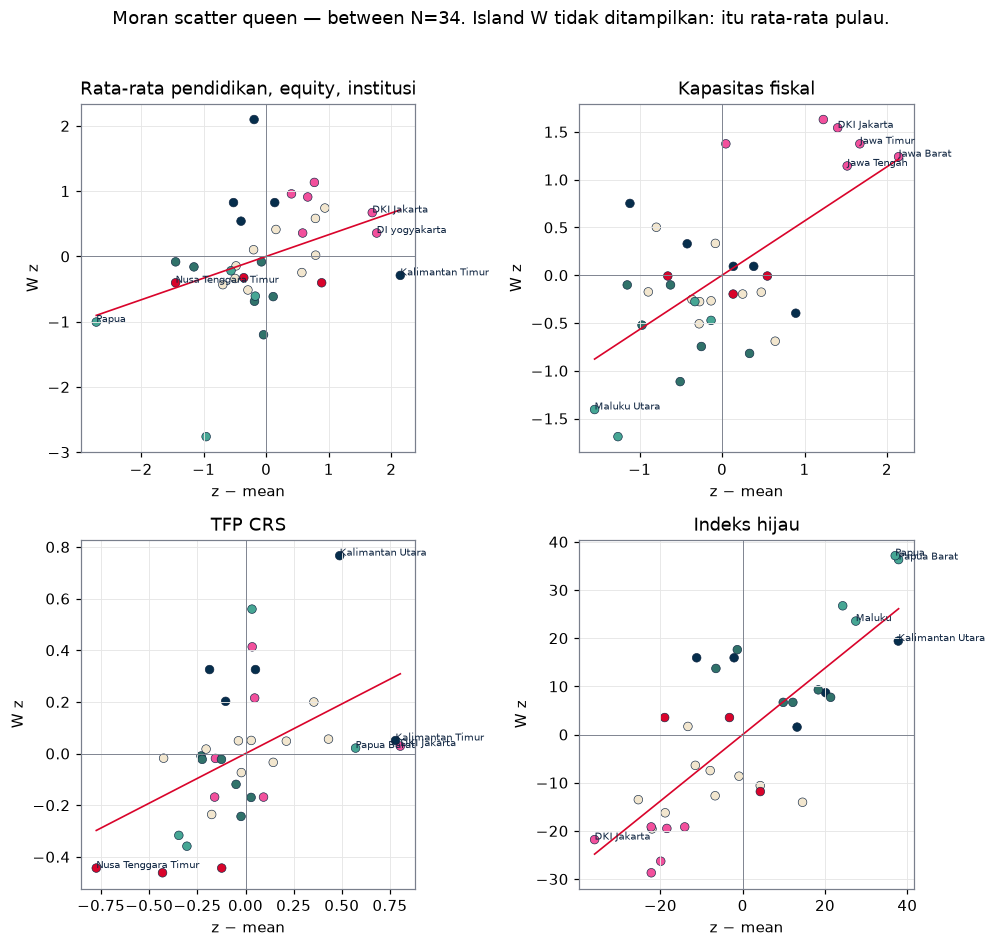

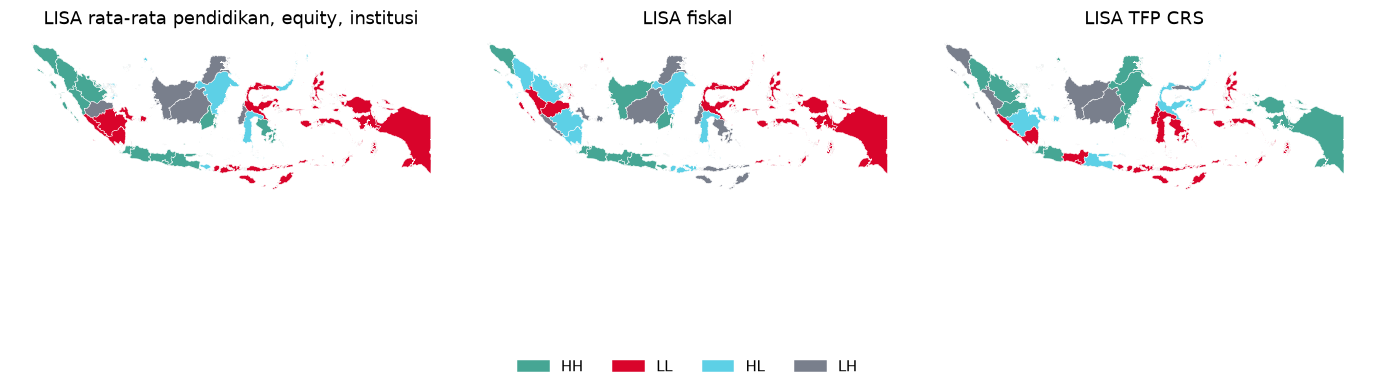

In [12]:
# Moran scatter: solow, fiskal, CRS, hijau
fig, axes = plt.subplots(2, 2, figsize=(9.2, 8.4))
pairs = [("idx_solow", "Rata-rata pendidikan, equity, institusi"), ("idx_fiskal", "Kapasitas fiskal"),
         ("logtfp_it_crs", "TFP CRS"), ("indeks_hijau", "Indeks hijau")]
for ax, (col, title) in zip(axes.ravel(), pairs):
    z = g.set_index("Code_Prov").loc[codes, col].to_numpy(float)
    wz = Wq @ z
    zc, wzc = z - z.mean(), wz - wz.mean()
    ax.scatter(zc, wzc, c=[PULAU_COLOR.get(p, GRAY) for p in g.set_index("Code_Prov").loc[codes, "Pulau"]],
               s=32, edgecolor=NAVY, lw=0.4)
    b, a = np.polyfit(zc, wzc, 1)
    xx = np.linspace(zc.min(), zc.max(), 40)
    ax.plot(xx, a + b * xx, color=RED, lw=1.1)
    ax.axhline(0, color=GRAY, lw=0.6); ax.axvline(0, color=GRAY, lw=0.6)
    I, p = moran_perm(z, Wq, n=499)
    ax.set_title(title)
    ax.set_xlabel("z − mean"); ax.set_ylabel("W z")
    for lab, zi, wzi in zip(g.set_index("Code_Prov").loc[codes, "Pre_Prov"], zc, wzc):
        if abs(zi) > np.quantile(np.abs(zc), 0.85):
            ax.annotate(lab, (zi, wzi), fontsize=6.5, color=NAVY)
fig.suptitle("Moran scatter queen — between N=34. Island W tidak ditampilkan: itu rata-rata pulau.", y=1.02)
fig.tight_layout()
save(fig, "eda2_moran_scatter.png")
plt.show()

# LISA maps
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.6))
cmap_l = {"HH": TEAL, "LL": RED, "HL": CYAN, "LH": GRAY}
for ax, col, title in zip(axes, ["lisa_idx_solow", "lisa_idx_fiskal", "lisa_logtfp_it_crs"],
                          ["LISA rata-rata pendidikan, equity, institusi", "LISA fiskal", "LISA TFP CRS"]):
    g.plot(color=g[col].map(cmap_l), linewidth=0.3, edgecolor="white", ax=ax)
    ax.set_axis_off(); ax.set_title(title)
fig.legend(handles=[Patch(color=c, label=k) for k, c in cmap_l.items()],
           loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout()
save(fig, "eda2_lisa_kuadran.png")
plt.show()


## Fiskal, PAD, belanja, dan SLX


wrote 01 Data/TFP/output/eda/eda2_fiskal_solow_pk.png
wrote 01 Data/TFP/output/eda/eda2_coef_KL.png
wrote 01 Data/TFP/output/eda/eda2_coef_slx.png
wrote 01 Data/TFP/output/eda/eda2_coef_investasi.png


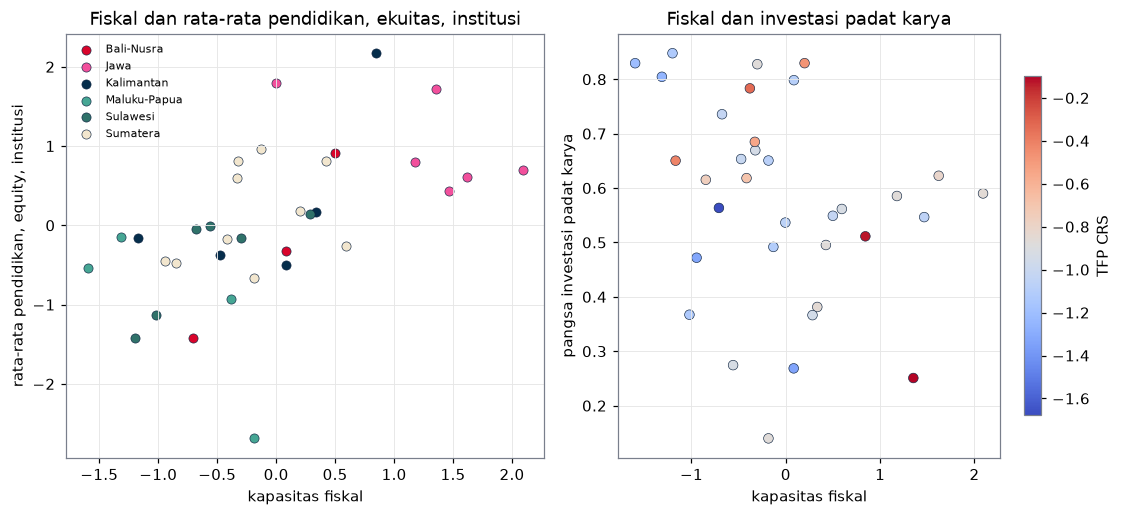

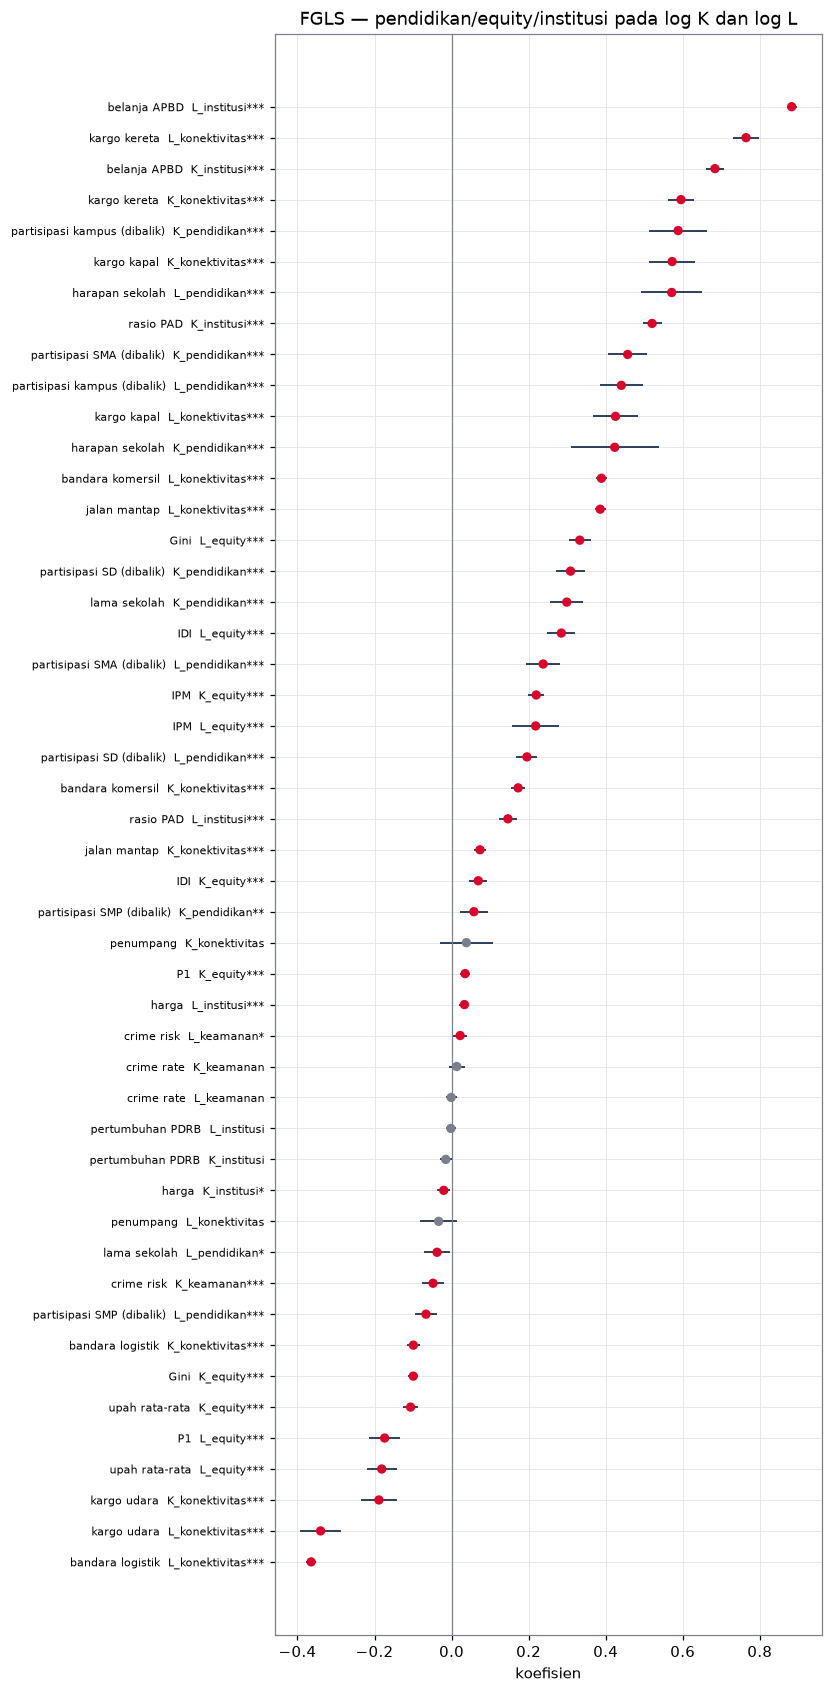

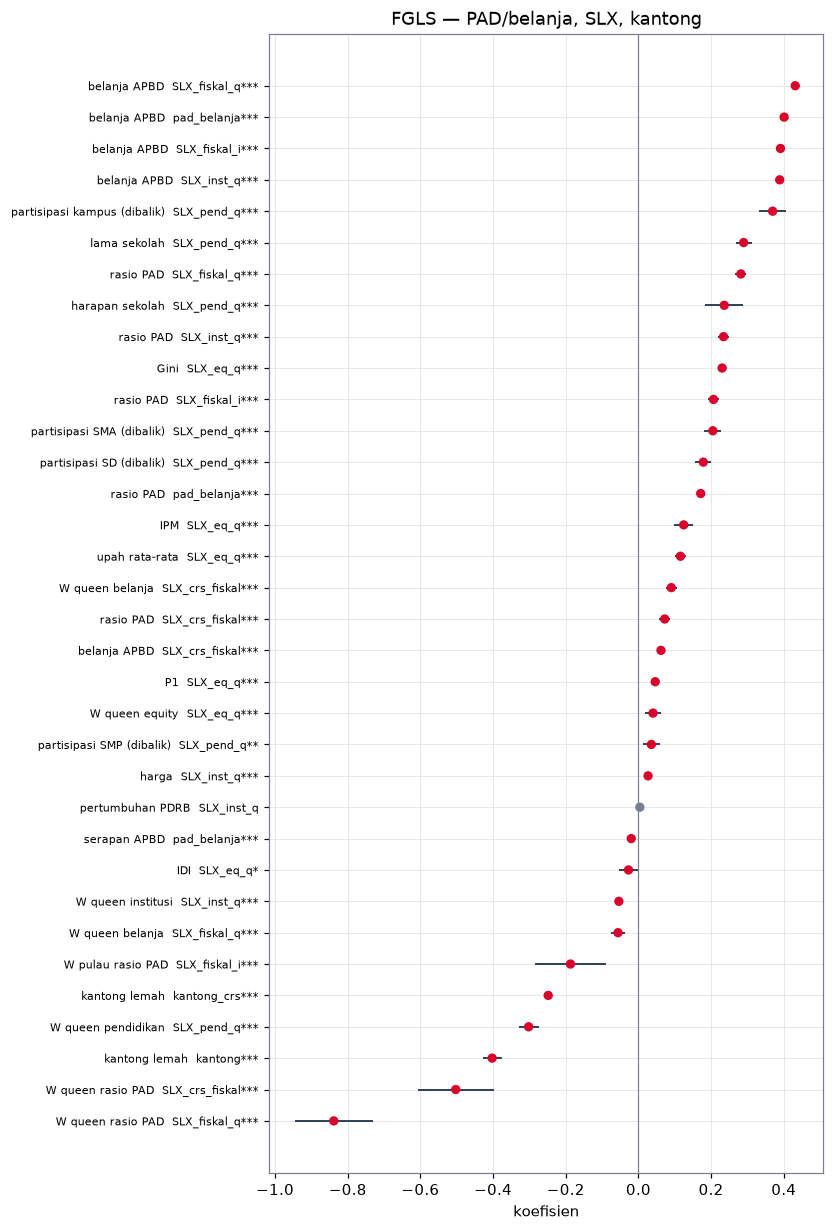

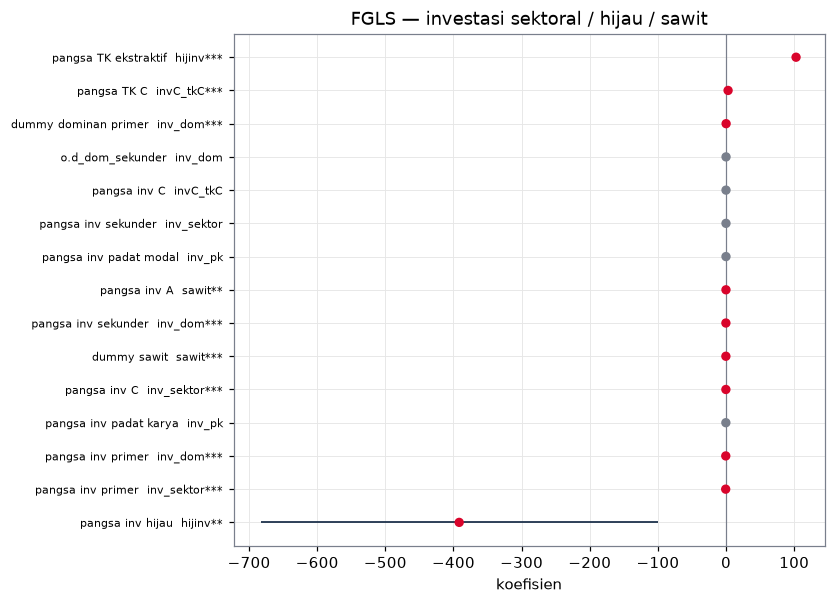

   Code_Prov  pilar_pendidikan  pilar_equity  pilar_institusi  pilar_konektivitas  pilar_lingkungan  pilar_keamanan  idx_solow  idx_hard  idx_fiskal  logtfp_it  logtfp_it_crs  indeks_hijau  rasio_pad  ln_apbd_belanja  apbd_serapan  share_tk_primer  share_tk_ekstraktif  share_inv_padat_karya  share_inv_A  Wq_pilar_pendidikan  Wq_pilar_equity  Wq_pilar_institusi  Wq_pilar_konektivitas  Wq_pilar_lingkungan  Wq_pilar_keamanan  Wq_idx_solow  Wq_idx_fiskal  Wq_logtfp_it  Wq_logtfp_it_crs  Wq_indeks_hijau  Wq_rasio_pad  Wq_share_tk_primer  Wq_ln_apbd_belanja  Wq_apbd_serapan  Wi_pilar_pendidikan  Wi_pilar_equity  Wi_pilar_institusi  Wi_idx_solow  Wi_idx_fiskal  Wi_logtfp_it  Wi_logtfp_it_crs  Wi_indeks_hijau  Wi_rasio_pad       Pre_Prov     Pulau  d_high_fiskal  d_high_solow  d_ekstraktif  d_sawit  d_hilir  d_dom_primer  d_dom_sekunder  top5_pendidikan  top5_equity  top5_institusi  top5_konektivitas  top5_lingkungan  top5_keamanan  bot5_pendidikan  bot5_equity  bot5_institusi  bot5_konektivit

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.8))
ax = axes[0]
for pulau, gg in pm.groupby("Pulau"):
    ax.scatter(gg["idx_fiskal"], gg["idx_solow"], s=36, color=PULAU_COLOR.get(pulau, GRAY),
               edgecolor=NAVY, lw=0.4, label=pulau)
ax.set_xlabel("kapasitas fiskal"); ax.set_ylabel("rata-rata pendidikan, equity, institusi")
ax.set_title("Fiskal dan rata-rata pendidikan, ekuitas, institusi")
ax.legend(frameon=False, fontsize=7)
ax = axes[1]
sc = ax.scatter(pm["idx_fiskal"], pm["share_inv_padat_karya"],
                c=pm["logtfp_it_crs"], cmap="coolwarm", s=40, edgecolor=NAVY, lw=0.4)
fig.colorbar(sc, ax=ax, shrink=0.8).set_label("TFP CRS")
ax.set_xlabel("kapasitas fiskal")
ax.set_ylabel("pangsa investasi padat karya")
ax.set_title("Fiskal dan investasi padat karya")
fig.tight_layout()
save(fig, "eda2_fiskal_solow_pk.png")
plt.show()

VARLAB = {
    "z_ln_lama_sekolah_mean": "lama sekolah",
    "z_ln_lama_sekolah_harapan": "harapan sekolah",
    "z_db_sd": "partisipasi SD (dibalik)",
    "z_db_smp": "partisipasi SMP (dibalik)",
    "z_db_sma": "partisipasi SMA (dibalik)",
    "z_db_kampus": "partisipasi kampus (dibalik)",
    "z_ln_p1": "P1",
    "z_ln_ipm": "IPM",
    "z_gini": "Gini",
    "z_ln_upah_rata": "upah rata-rata",
    "z_ln_indeks_demokrasi": "IDI",
    "z_price": "harga",
    "z_ln_rasio_pad": "rasio PAD",
    "z_ln_pertumbuhan_pdrb_adhb": "pertumbuhan PDRB",
    "z_ln_apbd_belanja": "belanja APBD",
    "z_ln_apbd_serapan": "serapan APBD",
    "z_ln_jalan_mantap": "jalan mantap",
    "z_ln_kargo_udara": "kargo udara",
    "z_ln_kargo_kapal": "kargo kapal",
    "z_ln_kargo_kereta": "kargo kereta",
    "z_ln_penumpang_total": "penumpang",
    "z_ln_airport_logistik": "bandara logistik",
    "z_ln_airport_komersil": "bandara komersil",
    "z_ln_indeks_lingkungan": "IKLH",
    "z_ln_indeks_hijau": "indeks hijau",
    "z_ln_indeks_biru": "indeks biru",
    "z_ln_crime_risk": "crime risk",
    "z_ln_crime_rate": "crime rate",
    "Wq_rasio_pad": "W queen rasio PAD",
    "Wq_ln_apbd_belanja": "W queen belanja",
    "Wi_rasio_pad": "W pulau rasio PAD",
    "Wq_pilar_pendidikan": "W queen pendidikan",
    "Wq_pilar_equity": "W queen equity",
    "Wq_pilar_institusi": "W queen institusi",
    "share_inv_padat_karya": "pangsa inv padat karya",
    "share_inv_padat_modal": "pangsa inv padat modal",
    "share_inv_primer": "pangsa inv primer",
    "share_inv_sekunder": "pangsa inv sekunder",
    "share_inv_C": "pangsa inv C",
    "share_inv_A": "pangsa inv A",
    "share_inv_hijau_inv": "pangsa inv hijau",
    "share_tk_C": "pangsa TK C",
    "share_tk_ekstraktif": "pangsa TK ekstraktif",
    "d_dom_primer": "dummy dominan primer",
    "d_dom_sekunder": "dummy dominan sekunder",
    "d_sawit": "dummy sawit",
    "kantong_lemah": "kantong lemah",
}

def _lab(v):
    return VARLAB.get(v, v.replace("z_ln_", "").replace("z_", ""))

coef2 = EVAL / "eval2_coef.csv"
if coef2.exists():
    c = pd.read_csv(coef2)

    def coefplot(sub, title, fname):
        if sub.empty:
            print("kosong", title)
            return
        sub = sub.copy()
        sub["lo"] = sub.b - 1.96 * sub.se
        sub["hi"] = sub.b + 1.96 * sub.se
        sub = sub.sort_values("b")
        fig, ax = plt.subplots(figsize=(7.6, max(3.4, 0.30 * len(sub) + 1.1)))
        y = np.arange(len(sub))
        ax.hlines(y, sub.lo, sub.hi, color=NAVY, lw=1.1)
        ax.scatter(sub.b, y, color=np.where(sub.p < 0.05, RED, GRAY), s=26, zorder=3)
        ax.axvline(0, color=GRAY, lw=0.8)
        ax.set_yticks(y)
        ax.set_yticklabels([f"{_lab(r.var)}  {r.model.replace('FGLS_', '')}{stars(r.p)}"
                            for r in sub.itertuples()], fontsize=7.5)
        ax.set_title(title)
        ax.set_xlabel("koefisien")
        fig.tight_layout()
        save(fig, fname)
        plt.show()

    kl = c[c.model.str.startswith("FGLS_K_") | c.model.str.startswith("FGLS_L_")]
    coefplot(kl, "FGLS — pendidikan/equity/institusi pada log K dan log L", "eda2_coef_KL.png")

    slx = c[c.model.str.contains("SLX|pad_belanja|kantong")]
    coefplot(slx, "FGLS — PAD/belanja, SLX, kantong", "eda2_coef_slx.png")

    inv = c[c.model.isin(["FGLS_inv_pk", "FGLS_inv_sektor", "FGLS_inv_dom",
                          "FGLS_invC_tkC", "FGLS_hijinv", "FGLS_sawit"])]
    coefplot(inv, "FGLS — investasi sektoral / hijau / sawit", "eda2_coef_investasi.png")
else:
    print("eval2_coef.csv belum ada — jalankan eval1.do lalu eval2.do")

bt = EVAL / "eval2_between.csv"
if bt.exists():
    btw = pd.read_csv(bt)
    display(btw.head())
